# Surface Precipitation in SuperdropNet experiments
- Figure 4 (zonal means)
- Figure 5 (frequency distribution)
- Figure S2 (precipitation maps)
- Figure S4 (zonal mean precipitation time step differences)

In [26]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import seaborn as sn
import numpy as np

In [ ]:
ref_60s_exp = "iconml_amip_2mom_reference_60s"
SDN_exp = "iconml_amip_superdropnet_sharma25_60s"
SDN_exp_1x60s = "iconml_amip_superdropnet_sharma25_60s_single_2ndtry" # first try: iconml_amip_superdropnet_sharma25_60s_single had wrong intital or boundary conditions
DATA_DIR = "../data/"
grid_file = "iconml_amip_2mom_reference/icon_grid_0054_R02B08_G.nc"
grid = xr.open_dataset(DATA_DIR + grid_file)
experiments = [ref_60s_exp, SDN_exp, SDN_exp_1x60s]
exp_names=["ref", "SDN", "SDN_1x60s"]

In [29]:
dayslice= slice('2020-01-17', '2020-01-22T00:00:00.000000000')

In [30]:
ds_list = []
for exp in experiments :
    #ds_list.append(xr.open_dataset(DATA_DIR + f"{exp}_atm_2d_P1D_pr_01deg.nc").drop_isel(time=[0,-1]) * 3600.)
    ds_list.append(xr.open_dataset(DATA_DIR + f"{exp}_atm_2d_P1D_pr_01deg.nc").sel(time=dayslice) * 3600.) 
atm_2d_1D = xr.concat(ds_list, dim = 'exp_name')
atm_2d_1D['exp_name'] = exp_names

In [32]:
IMERG = xr.open_mfdataset("../data/IMERG/3B-HHR.MS.MRG.3IMERG.202001*.nc4").sel(time=dayslice)
IMERG_timemean = IMERG.mean("time").compute()

HDF5-DIAG: Error detected in HDF5 (1.12.2) thread 165:
  #000: H5A.c line 528 in H5Aopen_by_name(): can't open attribute
    major: Attribute
    minor: Can't open object
  #001: H5VLcallback.c line 1091 in H5VL_attr_open(): attribute open failed
    major: Virtual Object Layer
    minor: Can't open object
  #002: H5VLcallback.c line 1058 in H5VL__attr_open(): attribute open failed
    major: Virtual Object Layer
    minor: Can't open object
  #003: H5VLnative_attr.c line 130 in H5VL__native_attr_open(): can't open attribute
    major: Attribute
    minor: Can't open object
  #004: H5Aint.c line 545 in H5A__open_by_name(): unable to load attribute info from object header
    major: Attribute
    minor: Unable to initialize object
  #005: H5Oattribute.c line 494 in H5O__attr_open_by_name(): can't locate attribute: '_QuantizeBitGroomNumberOfSignificantDigits'
    major: Attribute
    minor: Object not found
HDF5-DIAG: Error detected in HDF5 (1.12.2) thread 165:
  #000: H5A.c line 528 in 

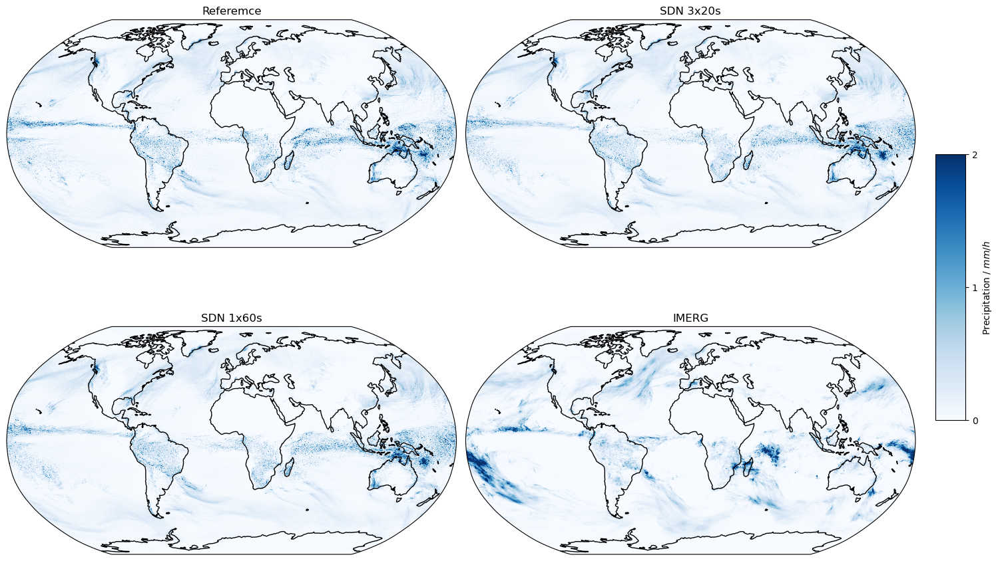

In [35]:
#fig, axes = plt.subplots(3, 1, figsize=(8, 12), subplot_kw={'projection': ccrs.Robinson(central_longitude=222)})
fig, axes = plt.subplots(2, 2, figsize=(15, 10), subplot_kw={'projection': ccrs.Robinson()})

axes=axes.flatten()

atm_2d_1D.sel(exp_name="ref").mean("time").pr.plot(x="lon", y="lat", vmin=0, vmax=2, cmap="Blues", transform=ccrs.PlateCarree(),ax=axes[0],add_colorbar=False )
im2 = atm_2d_1D.sel(exp_name="SDN").mean("time").pr.plot(x="lon", y="lat", vmin=0, vmax=2, cmap="Blues", transform=ccrs.PlateCarree(),ax=axes[1],add_colorbar=False)
im3 = atm_2d_1D.sel(exp_name="SDN_1x60s").mean("time").pr.plot(x="lon", y="lat", vmin=0, vmax=2, cmap="Blues", transform=ccrs.PlateCarree(),ax=axes[2],add_colorbar=False)
IMERG_timemean.precipitation.plot(x="lon", y="lat", vmin=0, vmax=2, cmap="Blues", transform=ccrs.PlateCarree(),ax=axes[3],add_colorbar=False)

axes[0].coastlines()
axes[1].coastlines()
axes[2].coastlines()
axes[3].coastlines()

axes[0].set_title("Referemce")
axes[1].set_title("SDN 3x20s")
axes[2].set_title("SDN 1x60s")
axes[3].set_title("IMERG")

plt.tight_layout()

# add space for colour bar
fig.subplots_adjust(right=0.92)
cbar_ax = fig.add_axes([0.94, 0.3, 0.03, 0.4])
fig.colorbar(im2, cax=cbar_ax, label="Precipitation / $mm/h$" ,ticks=[0,1,2], location="right")
fig.savefig("../plots/global_precip.png")

# Zonal Mean

In [38]:
imerg_zonmean_60 = IMERG_timemean.mean("lon").sel(lat=slice(-60,60)).compute()

imerg_zonmean_60["lat"] = atm_2d_1D.sel(lat=slice(-60,60)).lat

In [40]:
from scipy import stats

def welch_ttest_xr(da1, da2, dim="time"):
    """
    Welch's t-test between two DataArrays along `dim`, vectorized over
    any remaining dims (e.g. lat).
 
    Returns
    -------
    t_stat, p_value : xr.DataArray (dim removed)
    """
    def _welch(a, b):
        return stats.ttest_ind(a, b, axis=-1, equal_var=False, nan_policy="omit")
 
    t_stat, p_value = xr.apply_ufunc(
        _welch,
        da1, da2,
        input_core_dims=[[dim], [dim]],
        output_core_dims=[[], []],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float, float],
    )
    return t_stat, p_value


In [ ]:
t_SDN, p_SDN = welch_ttest_xr(atm_2d_1D.sel(exp_name="SDN").mean("lon").pr, atm_2d_1D.sel(exp_name="ref").mean("lon").pr)

significant_lats = atm_2d_1D.lat.values[p_SDN < 0.05]

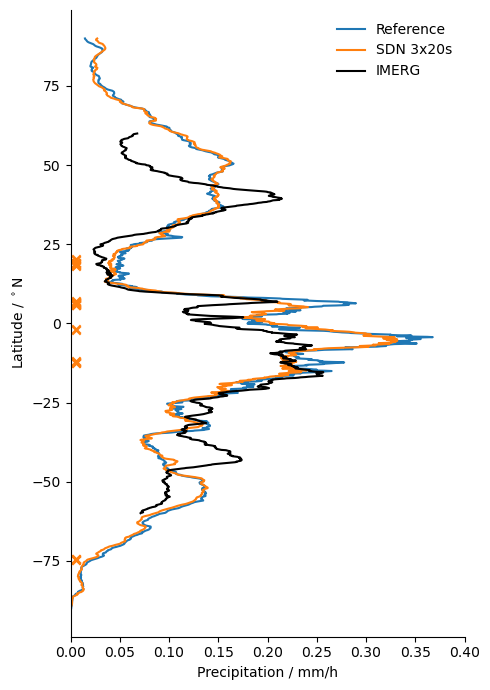

In [51]:
fig, axes = plt.subplots(1, 1, figsize=(5, 7), sharey=True)
sn.despine(fig=fig)

atm_2d_1D.sel(exp_name="ref").mean("time").mean("lon").pr.plot(y="lat",ax=axes,label="Reference" )
SDN = atm_2d_1D.sel(exp_name="SDN").mean("time").mean("lon").pr.plot(y="lat",ax=axes, label="SDN 3x20s", color="tab:orange")
#SDN_1x60 = atm_2d_1D.sel(exp_name="SDN_1x60s").mean("time").mean("lon").pr.plot(y="lat",ax=axes, label="SDN 1x60s",ls=":", color="tab:orange")
IMERG_im = imerg_zonmean_60.precipitation.plot(y="lat",ax=axes, label="IMERG", color="black")

plt.scatter(np.zeros_like(significant_lats)+0.005,significant_lats, color="tab:orange", marker="x")

axes.set_xlim(0,0.4)
axes.set_xlabel("Precipitation / mm/h")

axes.set_ylabel("Latitude / $^\circ$N")

axes.legend(frameon=False)

plt.tight_layout()

plt.savefig("../plots/precip_zonal_mean.png")

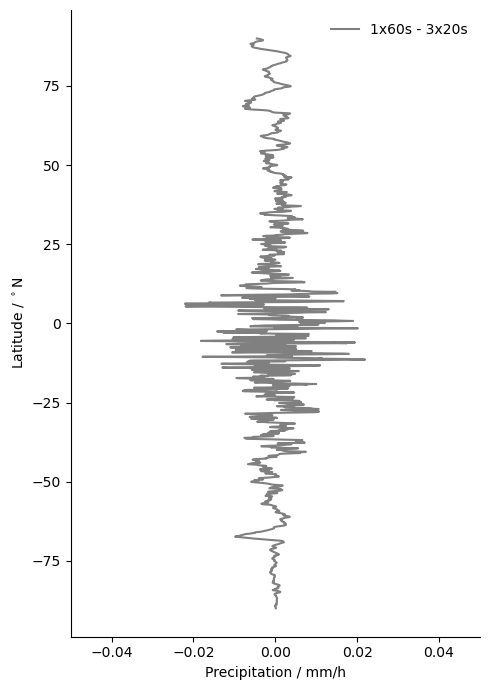

In [49]:
fig, axes = plt.subplots(1, 1, figsize=(5, 7), sharey=True)
sn.despine(fig=fig)

SDN = (atm_2d_1D.sel(exp_name="SDN_1x60s").mean("time").mean("lon").pr - atm_2d_1D.sel(exp_name="SDN").mean("time").mean("lon").pr).plot(y="lat",ax=axes, label="1x60s - 3x20s", color="grey")

axes.set_xlim(-0.05,0.05)
axes.set_xlabel("Precipitation / mm/h")

axes.set_ylabel("Latitude / $^\circ$N")

axes.legend(frameon=False)

plt.tight_layout()

plt.savefig("../plots/precip_zonal_mean_diff_timesteps.png")

# Frequency spectra with high freq data on native grid:

This calculation needs a lot of memory, more than 100GB!

In [53]:

dayslice= slice('2020-01-17', '2020-01-22T00:00:00.000000000')

ds_list = []
for exp in experiments :
    print(exp)
    ds = xr.open_dataset(DATA_DIR + f"{exp}_atm_2d_PT20M_pr_mergetime.nc")
    ds_list.append(ds.sel(time=dayslice) )

atm_2d_20m = xr.concat(ds_list, dim = 'exp_name').chunk({'exp_name' : 1}) * 3600.
atm_2d_20m['exp_name'] = exp_names

iconml_amip_2mom_reference_60s
iconml_amip_superdropnet_sharma25_60s
iconml_amip_superdropnet_sharma25_60s_single_2ndtry


In [54]:
%%time
atm_2d_3h = atm_2d_20m.resample(time='3h').mean().pr
atm_2d_6h = atm_2d_20m.resample(time='6h').mean().pr


CPU times: user 153 ms, sys: 27.1 ms, total: 180 ms
Wall time: 1.09 s


In [55]:
import numpy as np

def freq_spectra_numpy_ufunc(da) :
    '''
    
    inspired by Naumann et all: https://acp.copernicus.org/articles/25/6429/2025/

    '''
    flattened_data = da.flatten()
    rain = flattened_data[flattened_data > 0.1]
    
    pbin_edges = 10.**(np.arange(-1.,3.,0.15))
    pbin_widths = (pbin_edges[1:]-pbin_edges[:-1])
    pbin_centers = (pbin_edges[1:]+pbin_edges[:-1])*0.5
    hist_var, bin_edges = np.histogram(rain,bins=pbin_edges)#,density=True)
    hist_var = np.where(hist_var == 0., np.nan, hist_var)

    return hist_var
    

In [56]:
pbin_edges = 10.**(np.arange(-1.,3.,0.15))
pbin_widths = (pbin_edges[1:]-pbin_edges[:-1])
pbin_centers = (pbin_edges[1:]+pbin_edges[:-1])*0.5

### 3 hourly

#### add IMERG

In [58]:
IMERG = xr.open_mfdataset("../data/IMERG/3B-HHR.MS.MRG.3IMERG.202001*.nc4").sel(time=dayslice)

In [59]:
IMERG_3h = IMERG.resample(time='3h').mean().precipitation


#### 60N-60S

IMERG should not be trusted at higher latitudes than 60N

In [60]:
atm_2d_3h.coords["clat"] = ("ncells", grid.clat.values* 180. / np.pi) 
atm_2d_3h.coords["clon"] = ("ncells", grid.clon.values* 180. / np.pi)

In [61]:
atm_2d_3h_60 = atm_2d_3h.where((atm_2d_3h.clat > -60) & (atm_2d_3h.clat < 60), drop=True)
IMERG_3h_60 = IMERG_3h.sel(lat=slice(-60,60))

In [62]:
%%time

hist_var_3h_60 = xr.apply_ufunc(
    freq_spectra_numpy_ufunc,
    atm_2d_3h_60.compute(),
    input_core_dims=[['ncells','time']],
    output_core_dims=[['density']],
    vectorize=True,
)

CPU times: user 48.1 s, sys: 3min 6s, total: 3min 55s
Wall time: 21.8 s


In [63]:
hist_IMERG_3h_60= xr.apply_ufunc(
    freq_spectra_numpy_ufunc,
    IMERG_3h_60.compute(),
    input_core_dims=[['lon', 'lat','time']],
    output_core_dims=[['density']],
    vectorize=True,
)

HDF5-DIAG: Error detected in HDF5 (1.12.2) thread 220:
  #000: H5A.c line 528 in H5Aopen_by_name(): can't open attribute
    major: Attribute
    minor: Can't open object
  #001: H5VLcallback.c line 1091 in H5VL_attr_open(): attribute open failed
    major: Virtual Object Layer
    minor: Can't open object
  #002: H5VLcallback.c line 1058 in H5VL__attr_open(): attribute open failed
    major: Virtual Object Layer
    minor: Can't open object
  #003: H5VLnative_attr.c line 130 in H5VL__native_attr_open(): can't open attribute
    major: Attribute
    minor: Can't open object
  #004: H5Aint.c line 545 in H5A__open_by_name(): unable to load attribute info from object header
    major: Attribute
    minor: Unable to initialize object
  #005: H5Oattribute.c line 494 in H5O__attr_open_by_name(): can't locate attribute: '_QuantizeBitGroomNumberOfSignificantDigits'
    major: Attribute
    minor: Object not found
HDF5-DIAG: Error detected in HDF5 (1.12.2) thread 220:
  #000: H5A.c line 528 in 

#### Tropics

In [65]:
lat_band = 20

atm_2d_3h_trop = atm_2d_3h.where((atm_2d_3h.clat > -lat_band) & (atm_2d_3h.clat < lat_band), drop=True)
IMERG_3h_trop = IMERG_3h.sel(lat=slice(-lat_band,lat_band))

In [66]:
%%time

hist_var_3h_trop = xr.apply_ufunc(
    freq_spectra_numpy_ufunc,
    atm_2d_3h_trop.compute(),
    input_core_dims=[['ncells','time']],
    output_core_dims=[['density']],
    vectorize=True,
)

CPU times: user 55.8 s, sys: 3min 40s, total: 4min 35s
Wall time: 14.7 s


In [67]:
hist_IMERG_3h_trop = xr.apply_ufunc(
    freq_spectra_numpy_ufunc,
    IMERG_3h_trop.compute(),
    input_core_dims=[['lon', 'lat','time']],
    output_core_dims=[['density']],
    vectorize=True,
)

HDF5-DIAG: Error detected in HDF5 (1.12.2) thread 7:
  #000: H5A.c line 528 in H5Aopen_by_name(): can't open attribute
    major: Attribute
    minor: Can't open object
  #001: H5VLcallback.c line 1091 in H5VL_attr_open(): attribute open failed
    major: Virtual Object Layer
    minor: Can't open object
  #002: H5VLcallback.c line 1058 in H5VL__attr_open(): attribute open failed
    major: Virtual Object Layer
    minor: Can't open object
  #003: H5VLnative_attr.c line 130 in H5VL__native_attr_open(): can't open attribute
    major: Attribute
    minor: Can't open object
  #004: H5Aint.c line 545 in H5A__open_by_name(): unable to load attribute info from object header
    major: Attribute
    minor: Unable to initialize object
  #005: H5Oattribute.c line 494 in H5O__attr_open_by_name(): can't locate attribute: '_QuantizeBitGroomNumberOfSignificantDigits'
    major: Attribute
    minor: Object not found
HDF5-DIAG: Error detected in HDF5 (1.12.2) thread 7:
  #000: H5A.c line 528 in H5Ao

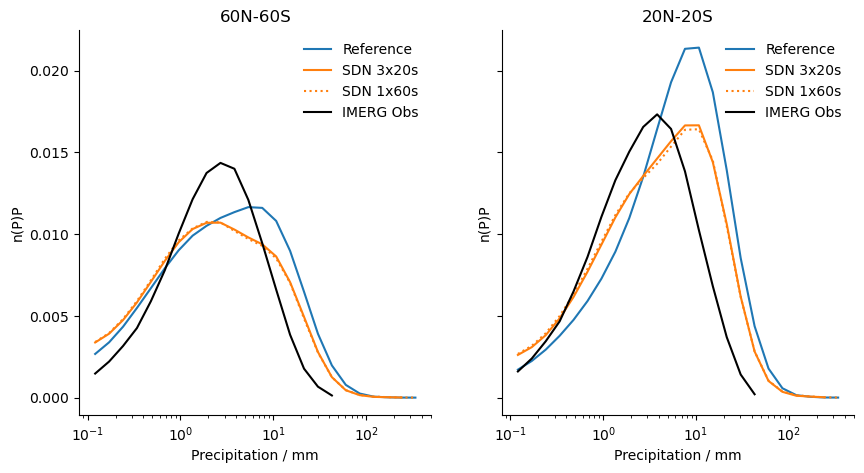

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(10, 5), sharey=True)
sn.despine(fig=fig)

ax=axes[0]
exp="ref"
hist = hist_var_3h_60.sel(exp_name=exp)
pr = atm_2d_3h_60.sel(exp_name=exp)
ax.plot(pbin_centers,hist*pbin_centers/np.size(pr), label = "Reference")

exp="SDN"
hist = hist_var_3h_60.sel(exp_name=exp)
pr = atm_2d_3h_60.sel(exp_name=exp)
ax.plot(pbin_centers,hist*pbin_centers/np.size(pr), label = "SDN 3x20s")

exp="SDN_1x60s"
hist = hist_var_3h_60.sel(exp_name=exp)
pr = atm_2d_3h_60.sel(exp_name=exp)
ax.plot(pbin_centers,hist*pbin_centers/np.size(pr), label = "SDN 1x60s", ls=":", color="tab:orange")

exp="IMERG Obs"
hist = hist_IMERG_3h_60
pr = IMERG_3h_60
ax.plot(pbin_centers,hist*pbin_centers/np.size(pr), label = exp, color="black")

ax.set_xlabel('Precipitation / mm')
ax.set_ylabel('n(P)P')
ax.legend(frameon=False)
ax.set_xscale('log')

ax.set_xscale('log')

ax.set_title("60N-60S")

ax=axes[1]
exp="ref"
hist = hist_var_3h_trop.sel(exp_name=exp)
pr = atm_2d_3h_trop.sel(exp_name=exp)
ax.plot(pbin_centers,hist*pbin_centers/np.size(pr), label = "Reference")

exp="SDN"
hist = hist_var_3h_trop.sel(exp_name=exp)
pr = atm_2d_3h_trop.sel(exp_name=exp)
ax.plot(pbin_centers,hist*pbin_centers/np.size(pr), label = "SDN 3x20s")

exp="SDN_1x60s"
hist = hist_var_3h_trop.sel(exp_name=exp)
pr = atm_2d_3h_trop.sel(exp_name=exp)
ax.plot(pbin_centers,hist*pbin_centers/np.size(pr), label = "SDN 1x60s", ls=":", color="tab:orange")

exp="IMERG Obs"
hist = hist_IMERG_3h_trop
pr = IMERG_3h_trop
ax.plot(pbin_centers,hist*pbin_centers/np.size(pr), label = exp, color="black")

ax.set_xlabel('Precipitation / mm')
ax.set_ylabel('n(P)P')
#ax.legend(frameon=False)
ax.set_xscale('log')

ax.set_xscale('log')
ax.set_title(f"{lat_band}N-{lat_band}S")

plt.savefig("../plots/precip_freq.png")